# Signed Counts: Why Clipping at Zero Biases Totals

Before OpenDP 0.16, a noisy count from `dp.len()` or `.dp.count()` could never be negative:
if the noise pushed a count below zero, OpenDP returned zero.
That looks sensible, since a real count can't be negative.
But it has a cost that is easy to miss.
Each clipped count is a little too high on average,
and when you add many clipped counts together, those small errors pile up.

OpenDP 0.16 adds a `signed` argument to the count functions.
With `signed=True`, negative noisy counts are kept.
This recipe shows where the bias of clipping comes from, how big it gets,
and when you should use each option.

A note on words: you may also see this called "clamping at zero".
Here "clipping" always means raising a negative noisy output to zero.
It is not the same as clipping each person's contribution before noise is added,
which is a different (and important) step in many DP analyses.

## The setup

Imagine a table of counts that is broken down finely:
50 regions times 8 categories gives 400 cells.
Most people fall into a few popular cells, so many cells are small or empty.
This is common in real releases: the more you break a table down, the more small cells you get.

We make up a dataset of 2,000 people. Region and category popularity both follow a long-tailed distribution.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import opendp.prelude as dp
import polars as pl

dp.enable_features("contrib")

rng = np.random.default_rng(42)

n_people = 2_000
regions = [f"region-{i:02d}" for i in range(50)]
categories = [f"category-{j}" for j in range(8)]


def long_tail(n):
    weights = 1 / np.arange(1, n + 1) ** 1.3
    return weights / weights.sum()


data = pl.LazyFrame(
    {
        "region": rng.choice(regions, size=n_people, p=long_tail(len(regions))),
        "category": rng.choice(categories, size=n_people, p=long_tail(len(categories))),
    }
)

The region and category names are public, so we can list every cell up front.
This matters: the list of keys must come from public knowledge, never from the data.
If we only released the cells that appear in the data, the list of cells itself would leak information.

We also compute the exact count in every cell.
These exact counts are not differentially private.
We use them only to measure how far the DP releases are from the truth;
a real analysis would never publish them.

In [2]:
keys = pl.LazyFrame({"region": regions}).join(
    pl.LazyFrame({"category": categories}), how="cross"
)

true_counts = (
    keys.join(
        data.group_by("region", "category").len(),
        on=["region", "category"],
        how="left",
    )
    .with_columns(pl.col("len").fill_null(0))
    .sort("region", "category")
    .collect()
)

print(f"{true_counts.height} cells")
print(f"{(true_counts['len'] == 0).sum()} are empty")
print(f"{(true_counts['len'] <= 3).sum()} have 3 or fewer people")

400 cells
145 are empty
311 have 3 or fewer people


## One release, two ways

Each person is in exactly one cell, so this table costs the same privacy budget as one count.
At $\epsilon = 1$, OpenDP adds integer Laplace noise with scale 1 to each cell.

We compare two versions of the same query:
`dp.len(signed=False)` clips negative noisy counts to zero,
and `dp.len(signed=True)` keeps them.

Passing the full list of keys with `.with_keys()` means empty cells get a noisy count too.
Here is the noise scale for one cell.
The `accuracy` column says that, with 95% confidence, each noisy cell is within that distance of its true count.

In [3]:
context = dp.Context.compositor(
    data=data,
    privacy_unit=dp.unit_of(contributions=1),
    privacy_loss=dp.loss_of(epsilon=1.0),
    split_evenly_over=1,
)

context.query().group_by("region", "category").agg(dp.len(signed=True)).with_keys(
    keys
).summarize(alpha=0.05)

column,aggregate,distribution,scale,accuracy
str,str,str,f64,f64
"""len""","""Frame Length""","""Integer Laplace""",1.0,3.375618


To compare the two options fairly, we release the same table many times with each.
In a real analysis you would release it once, and never report the un-noised values. Repeating it here lets us see
the average behavior of each option, which is what bias is about.

`query.resolve()` turns a query into an OpenDP measurement,
which we can call on the data as often as we like.
Every call is a fresh release with the same noise scale as above, and costs another $\epsilon = 1$.
Be careful: calling the measurement directly skips the Context's budget check entirely.
The 400 table releases below (200 for each option) add up to $\epsilon = 400$, and nothing stops or records that.
That is fine for a demonstration on made-up data. With real data, use `query.release()`,
which the Context checks against your budget, unless you track the budget yourself.

In [4]:
n_repeats = 200


def release_many(signed):
    query = (
        context.query()
        .group_by("region", "category")
        .agg(dp.len(signed=signed))
        .with_keys(keys)
    )
    measurement = query.resolve()
    releases = []
    for _ in range(n_repeats):
        released = measurement(data).collect().sort("region", "category")
        releases.append(released["len"].cast(pl.Int64).to_numpy())
    # one row per repeat, one column per cell
    return np.stack(releases)


signed_releases = release_many(signed=True)
clipped_releases = release_many(signed=False)
truth = true_counts["len"].to_numpy()

print("lowest signed count:", signed_releases.min())
print("lowest clipped count:", clipped_releases.min())

lowest signed count: -10
lowest clipped count: 0


## Where the bias comes from

Take a cell whose true count is $c$, and call the noise $Z$.
The signed release is $c + Z$. The noise is centered on zero, so on average the release equals $c$.

The clipped release is $\max(0, c + Z)$.
When $c$ is large, the noise almost never reaches zero, and clipping does nothing.
When $c$ is small, some draws land below zero and get raised up to zero.
Nothing ever pulls a release down to make up for that, so on average the clipped release is above $c$.

For integer Laplace noise with scale $b$, $P(Z = k) \propto e^{-|k|/b}$.
We can compute the expected clipped release exactly by summing over $k$,
and then check it against the releases above.

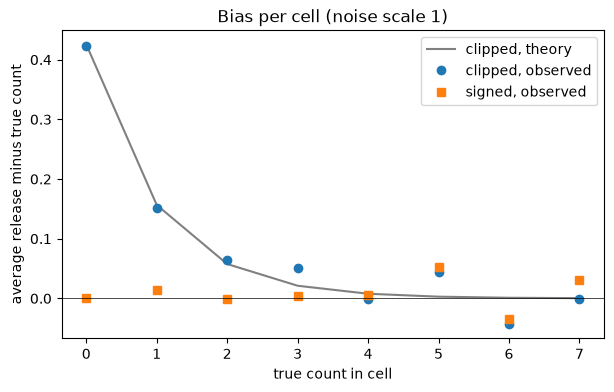

In [5]:
def expected_clipped(c, scale, k_max=200):
    k = np.arange(-k_max, k_max + 1)
    q = np.exp(-1 / scale)
    pmf = (1 - q) / (1 + q) * q ** np.abs(k)
    return np.sum(np.maximum(0, c + k) * pmf)


scale = 1.0
c_values = np.arange(0, 8)
theory_bias = [expected_clipped(c, scale) - c for c in c_values]

observed_clipped = [
    (clipped_releases[:, truth == c] - c).mean() if (truth == c).any() else np.nan
    for c in c_values
]
observed_signed = [
    (signed_releases[:, truth == c] - c).mean() if (truth == c).any() else np.nan
    for c in c_values
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(c_values, theory_bias, "-", color="gray", label="clipped, theory")
ax.plot(c_values, observed_clipped, "o", label="clipped, observed")
ax.plot(c_values, observed_signed, "s", label="signed, observed")
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlabel("true count in cell")
ax.set_ylabel("average release minus true count")
ax.set_title("Bias per cell (noise scale 1)")
ax.legend()
plt.show()

An empty cell comes out at about 0.43 on average when clipped, instead of 0.
By a true count of about 5 the bias is close to zero.
Signed counts sit near zero bias for every cell size.
The points that wander a little come from cell sizes with only a few cells, so they are just sampling noise.

## Clipping is not worse for one cell

Before we go further, it's worth being fair to clipping.
For a single cell, clipping never moves the release further from the truth:
the true count is at least zero, so raising a negative release up to zero can only bring it closer.

To see this without extra randomness getting in the way, we compare on the same noise draws:
we take the signed releases and clip them ourselves with `np.maximum(..., 0)`,
which gives the same distribution as `signed=False` in OpenDP.
Here is the average absolute error per cell for each option:

In [6]:
self_clipped = np.maximum(signed_releases, 0)

for c in [0, 1, 2, 5]:
    mask = truth == c
    if not mask.any():
        continue
    signed_err = np.abs(signed_releases[:, mask] - c).mean()
    clipped_err = np.abs(self_clipped[:, mask] - c).mean()
    print(
        f"true count {c}: signed error {signed_err:.2f}, clipped error {clipped_err:.2f}"
    )

true count 0: signed error 0.85, clipped error 0.43
true count 1: signed error 0.85, clipped error 0.70
true count 2: signed error 0.84, clipped error 0.79
true count 5: signed error 0.83, clipped error 0.83


So if your readers look at one cell at a time and would be confused by a negative count,
clipping is a reasonable choice. The problem starts when someone adds cells together.

## What happens when you add cells

Suppose a reader of our table wants the total number of people.
The natural thing is to add up all 400 cells.

With signed counts, the errors in each cell are independent and centered on zero,
so the error in the total stays centered on zero.
Its typical size grows only with the square root of the number of cells.

With clipped counts, every small cell adds its own positive bias.
Bias doesn't cancel, so it grows in step with the number of small cells.
(Large cells add almost nothing: by a true count of 5 the bias per cell is about 0.003.)

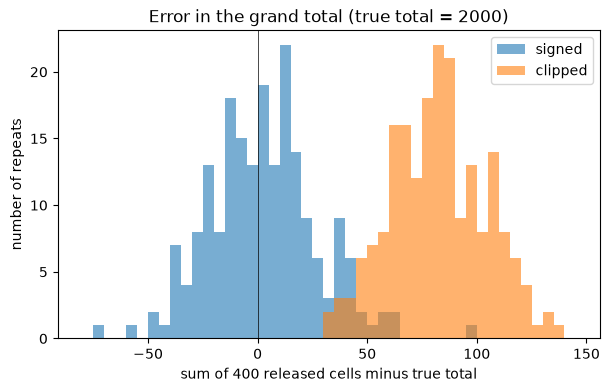

signed:  average error +2.2
clipped: average error +81.8
clipped, predicted from theory: +80.8
repeats where the clipped total was too high: 100%
repeats where the signed total was too high: 54%


In [7]:
true_total = truth.sum()
signed_total_error = signed_releases.sum(axis=1) - true_total
clipped_total_error = clipped_releases.sum(axis=1) - true_total
predicted_total_bias = sum(expected_clipped(c, scale) - c for c in truth)

fig, ax = plt.subplots(figsize=(7, 4))
all_errors = np.concatenate([signed_total_error, clipped_total_error])
bins = np.arange(all_errors.min() - 5, all_errors.max() + 10, 5)
ax.hist(signed_total_error, bins=bins, alpha=0.6, label="signed")
ax.hist(clipped_total_error, bins=bins, alpha=0.6, label="clipped")
ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel("sum of 400 released cells minus true total")
ax.set_ylabel("number of repeats")
ax.set_title(f"Error in the grand total (true total = {true_total})")
ax.legend()
plt.show()

print(f"signed:  average error {signed_total_error.mean():+.1f}")
print(f"clipped: average error {clipped_total_error.mean():+.1f}")
print(f"clipped, predicted from theory: {predicted_total_bias:+.1f}")
print(
    f"repeats where the clipped total was too high: {(clipped_total_error > 0).mean():.0%}"
)
print(
    f"repeats where the signed total was too high: {(signed_total_error > 0).mean():.0%}"
)

The clipped total is too high in essentially every repeat, by roughly the amount the theory predicts.
The signed total is sometimes high and sometimes low.
Its average over 200 repeats lands within a few people of zero, which is the size of difference that random noise alone produces.

The same thing happens at every level of the table.
A region total built from 8 clipped cells is biased upward,
and the bias is largest for the small regions, where it is the biggest share of the count.

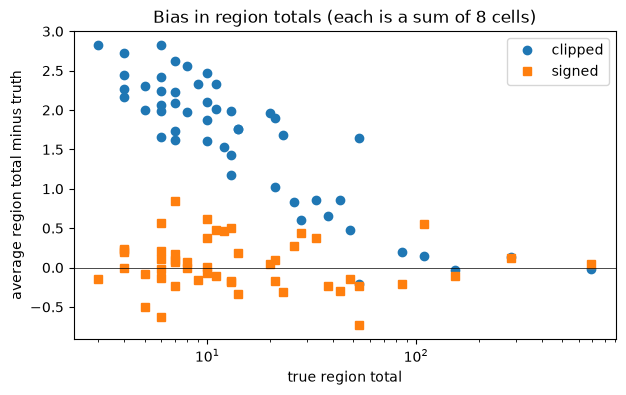

In [8]:
cells_per_region = len(categories)
region_truth = truth.reshape(len(regions), cells_per_region).sum(axis=1)
region_signed = signed_releases.reshape(n_repeats, len(regions), cells_per_region).sum(
    axis=2
)
region_clipped = clipped_releases.reshape(
    n_repeats, len(regions), cells_per_region
).sum(axis=2)

fig, ax = plt.subplots(figsize=(7, 4))
order = np.argsort(region_truth)
ax.plot(
    region_truth[order],
    (region_clipped.mean(axis=0) - region_truth)[order],
    "o",
    label="clipped",
)
ax.plot(
    region_truth[order],
    (region_signed.mean(axis=0) - region_truth)[order],
    "s",
    label="signed",
)
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("true region total")
ax.set_ylabel("average region total minus truth")
ax.set_title("Bias in region totals (each is a sum of 8 cells)")
ax.legend()
plt.show()

## Takeaways

- Clipping each count at zero makes each count look right and never makes a single count less accurate.
- But clipped counts are biased upward, and the bias adds up when counts are summed.
  With many small cells, the sum can be far off, always in the same direction.
- If anyone might add up, average, or model your counts, release them with `signed=True`.
  You can still clip at the very end, for display, after any sums are done.
  Clipping a released value is post-processing, so it costs no extra privacy budget.
- If you need both a clean-looking table and accurate totals,
  another option is to release the totals as their own queries,
  instead of asking readers to add up clipped cells.
  Those queries need their own share of the privacy budget, so plan for them when you create the Context
  (for example with `split_evenly_over=2`). The released totals also won't exactly equal the sum of the released cells.
- Whichever you choose, always pass `signed` explicitly, so your code means the same thing in every OpenDP version.